# Side experiments

Supporting runs around the main result: reward and information ablations, other RL algorithms, and training curves. The main results are in `main_results.ipynb`.

In [ ]:
import os, sys
os.environ["OMP_NUM_THREADS"] = "1"
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.utils import set_random_seed

from components.MicrogridEnv import GridEnv
from components.RL_helper import eval_one_episode_RL, eval_one_episode_rule_based
from components.XAI import build_reward_df, print_policy_metrics
from experiments.common import build_train_eval_configs, eval_windows, _load_full_df, _slice_to_config
from experiments.pure_rl_search import obs_norm_from, _quiet

torch.set_num_threads(1)
os.makedirs("models", exist_ok=True)

from stable_baselines3 import DDPG, TD3, SAC, DQN
from stable_baselines3.common.noise import NormalActionNoise
from stable_baselines3.common.callbacks import BaseCallback
from experiments.discretize import DiscretizeActionWrapper

In [ ]:
_, _, train_df, eval_df = build_train_eval_configs()
test_series = _load_full_df().loc[eval_df.index[0]: eval_df.index[-1] + pd.Timedelta(days=1)]  # +1 day for the lookahead
train_cfg, test_cfg = _slice_to_config(train_df), _slice_to_config(test_series)
windows = eval_windows(eval_df, n_windows=4, days=7)
norm = obs_norm_from(train_df)

print("train:", train_df.index[0], "->", train_df.index[-1])
print("test: ", eval_df.index[0], "->", eval_df.index[-1])

train: 2023-04-15 04:00:00 -> 2023-08-18 03:45:00
test:  2023-08-18 04:00:00 -> 2023-09-18 09:45:00


In [ ]:
LA = (2, 4, 8, 12, 16, 24, 32, 40)   # 0.5 h ... 10 h of day-ahead prices
OBS = dict(time_features=True, price_lookahead_steps=LA, obs_norm=norm)
BILL = dict(import_coeff=1.0, export_coeff=1.0, charge_from_grid_penalty_coeff=0.0,
            discharge_to_grid_penalty_coeff=0.0, limit_action_penalty_coeff=0.05, export_pv_coeff=0.0)

In [ ]:
def weekly_profit(model, obs_kw, wrap=lambda env: env):
    out = []
    for ws, we in windows:
        env = wrap(GridEnv(test_cfg, **obs_kw))
        _quiet(eval_one_episode_RL, env, policy=model, start_date=ws, end_date=we)
        out.append(float(_quiet(print_policy_metrics, build_reward_df(env))["financial_total"]))
    return out

In [ ]:
rule_based = []
for ws, we in windows:
    env = GridEnv(test_cfg)
    _quiet(eval_one_episode_rule_based, env, start_date=ws, end_date=we)
    rule_based.append(float(_quiet(print_policy_metrics, build_reward_df(env))["financial_total"]))
rb_mean = np.mean(rule_based)

def summarise(profits):
    per_seed = pd.Series({s: np.mean(v) for s, v in profits.items()})
    t, p = stats.ttest_1samp(per_seed, rb_mean)
    return dict(mean=per_seed.mean(), std=per_seed.std(), vs_rule=per_seed.mean() - rb_mean, p=p)

ALGOS = dict(ppo=PPO, ddpg=DDPG, td3=TD3, sac=SAC, dqn=DQN)

def fit(algo, obs_kw, reward, seed, steps, n_bins=7):
    torch.set_num_threads(1)
    set_random_seed(seed)

    def make():
        env = GridEnv(train_cfg, **obs_kw, **reward)
        if algo == "dqn":
            env = DiscretizeActionWrapper(env, n_bins=n_bins)
        env.reset(seed=seed)
        return env

    extra = {}
    if algo in ("td3", "ddpg"):
        extra["action_noise"] = NormalActionNoise(mean=np.zeros(1), sigma=0.1 * np.ones(1))
    model = ALGOS[algo]("MlpPolicy", DummyVecEnv([make]), seed=seed, device="cpu", verbose=0, **extra)
    model.learn(total_timesteps=steps)
    wrap = (lambda e: DiscretizeActionWrapper(e, n_bins=n_bins)) if algo == "dqn" else (lambda e: e)
    return weekly_profit(model, obs_kw, wrap)

## Ablations

Same PPO budget as the main model. Removing the price lookahead, or replacing the bill reward with the original penalised reward, removes most of the gain.

In [ ]:
STEPS, SEEDS = 300_000, [0, 1, 2, 3, 4]

ABLATIONS = {
    "bill reward, lookahead (main)": (OBS, BILL),
    "bill reward, no lookahead": (dict(time_features=True, obs_norm=norm), BILL),
    "penalised reward, lookahead": (dict(price_lookahead_steps=LA, obs_norm=norm), {}),
}
jobs = [(k, s) for k in ABLATIONS for s in SEEDS]
out = Parallel(n_jobs=-1)(delayed(fit)("ppo", *ABLATIONS[k], s, STEPS) for k, s in jobs)

abl = {k: {} for k in ABLATIONS}
for (k, s), v in zip(jobs, out):
    abl[k][s] = v
pd.DataFrame({k: summarise(v) for k, v in abl.items()}).T.round(3)

,mean,std,vs_rule,p
"bill reward, lookahead (main)",-32.678,2.634,11.327,0.001
"bill reward, no lookahead",-40.672,1.785,3.332,0.014
"penalised reward, lookahead",-45.610,2.151,-1.606,0.170


## Other RL algorithms

Same environment, reward and observations as the main model; off-policy methods get 100k steps and three seeds. DQN needs a discrete action, so the battery power is cut into 7 levels.

In [ ]:
OFF_STEPS, OFF_SEEDS = 100_000, [0, 1, 2]

jobs = [(a, s) for a in ("ddpg", "td3", "sac", "dqn") for s in OFF_SEEDS]
out = Parallel(n_jobs=-1)(delayed(fit)(a, OBS, BILL, s, OFF_STEPS) for a, s in jobs)

algos = {a: {} for a in ("ddpg", "td3", "sac", "dqn")}
for (a, s), v in zip(jobs, out):
    algos[a][s] = v
algos["ppo"] = abl["bill reward, lookahead (main)"]
pd.DataFrame({k: summarise(v) for k, v in algos.items()}).T.sort_values("mean", ascending=False).round(3)

,mean,std,vs_rule,p
ppo,-32.678,2.634,11.327,0.001
ddpg,-39.299,4.718,4.705,0.226
td3,-41.790,3.771,2.215,0.416
dqn,-42.895,3.054,1.109,0.594
sac,-49.214,1.391,-5.209,0.023


## Training curves

Weekly-equivalent return of each training episode (one pass over the training period) for the main configuration.

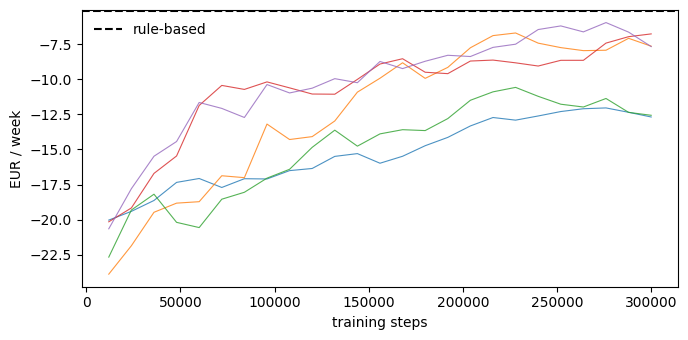

In [ ]:
class EpisodeReturn(BaseCallback):
    def __init__(self):
        super().__init__()
        self.rows, self.ret, self.n = [], 0.0, 0

    def _on_step(self):
        self.ret += float(self.locals["rewards"][0])
        self.n += 1
        if bool(self.locals["dones"][0]):
            self.rows.append((self.num_timesteps, self.ret / self.n * 672))   # 672 steps per week
            self.ret, self.n = 0.0, 0
        return True

def curve(seed):
    torch.set_num_threads(1)
    set_random_seed(seed)

    def make():
        env = GridEnv(train_cfg, **OBS, **BILL)
        env.reset(seed=seed)
        return env

    cb = EpisodeReturn()
    PPO("MlpPolicy", DummyVecEnv([make]), seed=seed, device="cpu", verbose=0).learn(STEPS, callback=cb)
    return pd.DataFrame(cb.rows, columns=["steps", "weekly_return"]).assign(seed=seed)

curves = pd.concat(Parallel(n_jobs=len(SEEDS))(delayed(curve)(s) for s in SEEDS))

rb_train = []
env = GridEnv(train_cfg)
_quiet(eval_one_episode_rule_based, env, start_date=train_df.index[0], end_date=train_df.index[-1])
rb_train = float(_quiet(print_policy_metrics, build_reward_df(env))["financial_total"]) / (len(train_df) / 672)

fig, ax = plt.subplots(figsize=(7, 3.5))
for s, d in curves.groupby("seed"):
    ax.plot(d["steps"], d["weekly_return"], lw=0.8, alpha=0.8)
ax.axhline(rb_train, c="k", ls="--", label="rule-based")
ax.set_xlabel("training steps"); ax.set_ylabel("EUR / week"); ax.legend(frameon=False)
plt.tight_layout()